# Obs. diagnosis: leave-one-out analysis of BHM GDP per capita regressions
Adapted from Tom's code

In [69]:
from __future__ import annotations

import os
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import TwoSlopeNorm, SymLogNorm, Normalize, LinearSegmentedColormap
from matplotlib.lines import Line2D
from scipy import sparse
from scipy.sparse.linalg import lsqr
from scipy import stats as sps
import sklearn
from cartopy import crs as ccrs
import cmocean
from funcs_plot import create_segcmap,add_colorbar

import geopandas as gpd
import string


from funcs_support import get_params,get_filepaths,load_shp,utility_print
from funcs_readregs import coeffs_gdppc
dir_list = get_params()


extra_fonts = {'lato':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Regular.ttf'),
 'lato-bold':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Bold.ttf')}


In [4]:
# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------

DROPBOX = Path(os.environ.get(
    "KS_DROPBOX", dir_list['proc']))
REPO    = Path(os.environ.get(
    "KS_REPO",    "/glade/u/home/schwarzwald/projects/impact_uncertainty"))

REG_INPUT = DROPBOX / "reg_inputs"  / "gdppc" / "reginputs_gdppc_025deg.csv"
FULL_DIR  = DROPBOX / "reg_outputs" / "gdppc"
LOO_DIR   = DROPBOX / "reg_outputs" / "gdppc" / "loos"
SHP       = REPO / "aux_data" / "geo_data" / "country-fixed.shp"

OUT_DIR   = Path(dir_list['figs'])
OUT_FIG1  = OUT_DIR / "extdata_fig1_temp_disagreement.pdf"
OUT_FIG2  = OUT_DIR / "extdata_fig2_me_disagreement.pdf"

# The 4 main reanalyses; filenames use "ERA5-025" but we display "ERA5".
REANALYSES = ("ERA5-025", "MERRA2", "JRA-3Q", "GMFD")
LABEL  = {"ERA5-025": "ERA5", "MERRA2": "MERRA2",
          "JRA-3Q": "JRA-3Q", "GMFD": "GMFD"}
# Colour-blind-friendly four-tone palette (Wong 2011)
COLOUR = {"ERA5-025": "#E69F00",   # orange
          "MERRA2":   "#0072B2",   # blue
          "JRA-3Q":   "#009E73",   # green
          "GMFD":     "#CC79A7"}   # magenta

YEAR_LO, YEAR_HI = 1980, 2010

# 6 unordered pairs in a canonical order (smallest baseline first)
PAIR_ORDER = [
    ("MERRA2", "GMFD"),
    ("JRA-3Q", "ERA5-025"),
    ("MERRA2", "ERA5-025"),
    ("GMFD",   "ERA5-025"),
    ("MERRA2", "JRA-3Q"),
    ("JRA-3Q", "GMFD"),
]

# Publication-quality matplotlib defaults
plt.rcParams.update({
    "font.family":      "sans-serif",
    "font.sans-serif":  ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size":        8.5,
    "axes.labelsize":   9,
    "axes.titlesize":   9.5,
    "xtick.labelsize":  7.5,
    "ytick.labelsize":  7.5,
    "legend.fontsize":  8,
    "figure.titlesize": 11,
    "pdf.fonttype":     42,   # embed TrueType (editable in Illustrator)
    "ps.fonttype":      42,
    "savefig.bbox":     "tight",
})



In [5]:
# ---------------------------------------------------------------------------
# Loaders
# ---------------------------------------------------------------------------

_FULL_RE = re.compile(
    r"^regoutputs_coeffs_gdppc_025deg_(?P<rea>[^_]+)_1980-2010\.csv$")
_LOO_RE  = re.compile(
    r"^regoutputs_coeffs_gdppc_025deg_(?P<rea>[^_]+)_1980-2010_no(?P<country>.+)\.csv$")


def load_panel() -> pd.DataFrame:
    """BHM regression-input panel, balanced across the 4 main reanalyses."""
    use = ["countryname", "iso", "year", "obs_mod", "temp_popweight", "Pop",
           "growthWDI", "time", "time2", "gdpCAPppp_wdi",'og_insamp']
    df = pd.read_csv(REG_INPUT, usecols=use)
    df = df[(df["year"] >= YEAR_LO) & (df["year"] <= YEAR_HI)]
    df = df[df["obs_mod"].isin(REANALYSES)]
    df = df.dropna(subset=["temp_popweight"])

    # Drop locs not in the original sample
    df = df.where(df.og_insamp).dropna(how='all')
    
    # Require every reanalysis to observe each (iso, year)
    counts = df.groupby(["iso", "year"])["obs_mod"].nunique().reset_index()
    keep = counts[counts["obs_mod"] == len(REANALYSES)][["iso", "year"]]
    df = df.merge(keep, on=["iso", "year"], how="inner").reset_index(drop=True)
    return df


def load_full_coeffs() -> dict[str, tuple[float, float]]:
    out: dict[str, tuple[float, float]] = {}
    for fn in sorted(FULL_DIR.glob("regoutputs_coeffs_gdppc_025deg_*_1980-2010.csv")):
        m = _FULL_RE.match(fn.name)
        if not m or m.group("rea") not in REANALYSES:
            continue
        d = pd.read_csv(fn)
        out[m.group("rea")] = (float(d["b1"].iloc[0]), float(d["b2"].iloc[0]))
    missing = set(REANALYSES) - set(out)
    if missing:
        raise RuntimeError(f"missing full-sample coeffs for: {missing}")
    return out


def load_loo_coeffs() -> dict[tuple[str, str], tuple[float, float]]:
    out: dict[tuple[str, str], tuple[float, float]] = {}
    for fn in sorted(LOO_DIR.glob("regoutputs_coeffs_gdppc_*.csv")):
        m = _LOO_RE.match(fn.name)
        if not m or m.group("rea") not in REANALYSES:
            continue
        d = pd.read_csv(fn)
        out[(m.group("rea"), m.group("country"))] = (
            float(d["b1"].iloc[0]), float(d["b2"].iloc[0]))
    return out

In [6]:
# ---------------------------------------------------------------------------
# Residualisation: T ~ 1 | iso + year + iso[time1] + iso[time2]
#   (per reanalysis, using sparse OLS)
# ---------------------------------------------------------------------------

def residualise_one(df_rea: pd.DataFrame) -> np.ndarray:
    iso_c = pd.Categorical(df_rea["iso"])
    yr_c  = pd.Categorical(df_rea["year"])
    t1    = df_rea["time"].to_numpy(dtype=float)
    t2    = df_rea["time2"].to_numpy(dtype=float)
    n     = len(df_rea)
    rows  = np.arange(n)
    iso_codes, yr_codes = iso_c.codes, yr_c.codes
    n_iso, n_yr = len(iso_c.categories), len(yr_c.categories)
    iso_blk = sparse.csc_matrix((np.ones(n), (rows, iso_codes)), shape=(n, n_iso))
    yr_blk  = sparse.csc_matrix((np.ones(n), (rows, yr_codes )), shape=(n, n_yr))
    yr_blk  = yr_blk[:, 1:]   # drop one year for identification
    iso_t1  = sparse.csc_matrix((t1, (rows, iso_codes)), shape=(n, n_iso))
    iso_t2  = sparse.csc_matrix((t2, (rows, iso_codes)), shape=(n, n_iso))
    X = sparse.hstack([iso_blk, yr_blk, iso_t1, iso_t2]).tocsr()
    y = df_rea["temp_popweight"].to_numpy(dtype=float)
    beta = lsqr(X, y, atol=1e-10, btol=1e-10, iter_lim=20000)[0]
    return y - X @ beta


def residualise_all(df: pd.DataFrame) -> pd.DataFrame:
    parts = []
    for rea in REANALYSES:
        sub = df[df["obs_mod"] == rea].copy()
        sub["resid"] = residualise_one(sub)
        parts.append(sub[["countryname", "iso", "year", "obs_mod",
                          "temp_popweight", "resid"]])
    return pd.concat(parts, ignore_index=True)


# ---------------------------------------------------------------------------
# Pairwise quantities
# ---------------------------------------------------------------------------

def per_pair_country_mad(resid: pd.DataFrame) -> pd.DataFrame:
    """Per (pair, country): mean over years of |resid_a - resid_b|."""
    wide = resid.pivot_table(index=["iso", "countryname", "year"],
                             columns="obs_mod", values="resid").reset_index()
    rows = []
    for (a, b) in PAIR_ORDER:
        d = wide.dropna(subset=[a, b]).copy()
        d["d"] = (d[a] - d[b]).abs()
        m = (d.groupby(["iso", "countryname"], as_index=False)
              .agg(mad=("d", "mean")))
        m["pair_a"] = a; m["pair_b"] = b
        rows.append(m)
    return pd.concat(rows, ignore_index=True)


def country_covariates(df: pd.DataFrame) -> pd.DataFrame:
    sub = df[df["obs_mod"] == REANALYSES[0]]
    g = (sub.groupby(["iso", "countryname"])
            .agg(mean_T=("temp_popweight", "mean"),
                 mean_gdp=("gdpCAPppp_wdi", "mean"))
            .reset_index())
    g["log_gdp"] = np.log(g["mean_gdp"])
    return g


# ---------------------------------------------------------------------------
# L1 distance between marginal-effect curves (uniform weighting)
# ---------------------------------------------------------------------------

def _me(b1: float, b2: float, t: np.ndarray) -> np.ndarray:
    """BHM marginal effect dy/dT = b1 + 2 b2 T."""
    return b1 + 2.0 * b2 * t


def pair_l1_uniform(coef_a, coef_b, panel, pair) -> float:
    """L1 between MEs of the two reanalyses in `pair`, integrated UNIFORMLY
    over the empirical T sample from rows of `panel` belonging to either
    reanalysis."""
    a, b = pair
    s = panel[panel["obs_mod"].isin((a, b))]
    if s.empty:
        return float("nan")
    t = s["temp_popweight"].to_numpy()
    return float(np.mean(np.abs(_me(*coef_a, t) - _me(*coef_b, t))))


def compute_perpair_abs_reduction(panel: pd.DataFrame,
                                   full: dict, loo: dict) -> pd.DataFrame:
    """For each (pair, country): abs_reduction = L1_full − L1_drop_country,
    in raw L1 units (same scale across pairs).  Includes loo_id == 'all'
    rows for the per-pair baselines (abs_reduction = 0)."""
    countries = sorted(panel["countryname"].unique())
    rows = []
    for (a, b) in PAIR_ORDER:
        L1_full = pair_l1_uniform(full[a], full[b], panel, (a, b))
        rows.append({"pair_a": a, "pair_b": b, "country": "all",
                     "L1": L1_full, "abs_reduction": 0.0})
        for c in countries:
            if (a, c) not in loo or (b, c) not in loo:
                continue
            sub = panel[panel["countryname"] != c]
            L1_c = pair_l1_uniform(loo[(a, c)], loo[(b, c)], sub, (a, b))
            rows.append({"pair_a": a, "pair_b": b, "country": c,
                         "L1": L1_c,
                         "abs_reduction": L1_full - L1_c})
    return pd.DataFrame(rows)


def compute_mean_abs_reduction(perpair: pd.DataFrame) -> pd.DataFrame:
    """Mean absolute reduction across the 6 pairs, per country."""
    d = perpair[perpair["country"] != "all"]
    return (d.groupby("country", as_index=False)
             .agg(mean_abs_reduction=("abs_reduction", "mean")))


# ---------------------------------------------------------------------------
# Small helpers
# ---------------------------------------------------------------------------

def _ols_overlay(ax, x, y, color="0.15", show_stats=False, loc="lower right"):
    """OLS fit dashed line. If show_stats=True, also write R² / p in a box
    at the given `loc` corner."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    m = np.isfinite(x) & np.isfinite(y)
    x, y = x[m], y[m]
    if x.size < 3:
        return
    r = sps.linregress(x, y)
    xs = np.linspace(x.min(), x.max(), 60)
    ax.plot(xs, r.slope * xs + r.intercept,
            color=color, linewidth=1.0, linestyle="--", zorder=2)
    if not show_stats:
        return
    p_txt = f"p < 0.001" if r.pvalue < 1e-3 else f"p = {r.pvalue:.2g}"
    anchors = {
        "upper right": (0.97, 0.96, "right", "top"),
        "upper left":  (0.03, 0.96, "left",  "top"),
        "lower right": (0.97, 0.04, "right", "bottom"),
        "lower left":  (0.03, 0.04, "left",  "bottom"),
    }
    ax_x, ax_y, ha, va = anchors[loc]
    ax.text(ax_x, ax_y,
            f"$R^2$ = {r.rvalue**2:.2f}\n{p_txt}",
            transform=ax.transAxes, ha=ha, va=va,
            fontsize=7, color=color,
            bbox=dict(boxstyle="round,pad=0.22",
                      facecolor="white", edgecolor="0.85", linewidth=0.4))


def _despine(ax, sides=("top", "right")):
    for s in sides:
        ax.spines[s].set_visible(False)


def load_shapefile() -> gpd.GeoDataFrame:
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore")
        gdf = gpd.read_file(SHP)
    gdf["geometry"] = gdf.make_valid()
    gdf = gdf.rename(columns={"CNTRY_NAME": "locid"})
    return gdf.query("locid != 'Antarctica'").reset_index(drop=True)


def _world_map(ax):
    ax.set_xlim(-180, 180)
    ax.set_ylim(-60, 85)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)


# ===========================================================================
# Figure 1 — temperature shock disagreement
# ===========================================================================

def build_fig1(resid: pd.DataFrame,
               pair_mad: pd.DataFrame,
               cov: pd.DataFrame) -> plt.Figure:

    # ---- Pick 2 most-agreeing + 2 most-disagreeing countries by avg MAD ----
    per_country = (pair_mad.groupby(["iso", "countryname"], as_index=False)
                            .agg(mean_mad=("mad", "mean")))
    per_country = per_country.merge(cov[["iso", "log_gdp"]], on="iso",
                                     how="left")
    # Require at least 25 years of residual data for sensible time-series panels
    yr_count = (resid.groupby("countryname")
                     .agg(n_years=("year", "nunique"))
                     .reset_index())
    per_country = per_country.merge(yr_count, on="countryname", how="left")
    per_country = per_country[per_country["n_years"] >= 25].reset_index(drop=True)

    agree = per_country.nsmallest(2, "mean_mad").sort_values("mean_mad")
    disagr = per_country.nlargest(2, "mean_mad").sort_values("mean_mad", ascending=False)
    print("Agreeing 2: " + ", ".join(agree["countryname"].tolist()))
    print("Disagreeing 2: " + ", ".join(disagr["countryname"].tolist()))
    panel_countries = (
        agree.assign(grp="most agreement").to_dict("records") +
        disagr.assign(grp="most disagreement").to_dict("records"))

    # ---- Build figure --------------------------------------------------
    fig = plt.figure(figsize=(7.0, 7.0))
    gs = GridSpec(3, 2, figure=fig,
                  height_ratios=[1.0, 1.0, 1.55],
                  hspace=0.50, wspace=0.28,
                  left=0.11, right=0.97, top=0.93, bottom=0.08)

    # ---- Time series of residuals (top 2x2 grid) -----------------------
    ts_letters = ["a", "b", "c", "d"]
    for k, row in enumerate(panel_countries):
        r, c = divmod(k, 2)
        ax = fig.add_subplot(gs[r, c])
        d_country = resid[resid["countryname"] == row["countryname"]]
        for rea in REANALYSES:
            d = d_country[d_country["obs_mod"] == rea].sort_values("year")
            if d.empty:
                continue
            ax.plot(d["year"], d["resid"],
                    color=COLOUR[rea], linewidth=0.9, alpha=0.95)
        ax.axhline(0, color="0.7", linewidth=0.4, zorder=0)
        ax.tick_params(labelsize=7)
        _despine(ax)
        ax.set_xlim(YEAR_LO - 0.5, YEAR_HI + 0.5)
        tag = "most agreement" if row["grp"] == "most agreement" else "most disagreement"
        ax.set_title(
            f"({ts_letters[k]})  {row['countryname']}  ({tag}; mean |Δresid T| = "
            f"{row['mean_mad']:.2f} °C)",
            fontsize=8.5, loc="left", pad=2)
        if c == 0:
            ax.set_ylabel("Residual T (°C)", fontsize=8.5)
        if r == 0:
            ax.set_xticklabels([])

    # ---- Shared 4-reanalysis legend strip across panel row -------------
    handles = [Line2D([0], [0], color=COLOUR[r], linewidth=1.6,
                       label=LABEL[r]) for r in REANALYSES]
    fig.legend(handles=handles, loc="upper center",
               ncol=4, frameon=False,
               bbox_to_anchor=(0.5, 0.985), fontsize=8.5)

    # ---- Bottom row: 2 scatters ----------------------------------------
    # Per-country mean MAD (across the 6 pairs) is the y-axis of both
    pc_x = per_country.merge(cov[["iso", "mean_T"]], on="iso", how="left")

    panels = [
        ("mean_T",  "Country-mean annual T (°C, 1980–2010)",
         "(e) vs. country-mean temperature"),
        ("log_gdp", "log mean GDP per capita (PPP, 1980–2010)",
         "(f) vs. country-mean log income"),
    ]
    for k, (x_col, x_lab, title) in enumerate(panels):
        ax = fig.add_subplot(gs[2, k])
        sub = pc_x.dropna(subset=[x_col])
        ax.scatter(sub[x_col], sub["mean_mad"],
                   s=12, color="0.35", alpha=0.7,
                   edgecolor="white", linewidth=0.3)
        _ols_overlay(ax, sub[x_col].to_numpy(), sub["mean_mad"].to_numpy())
        # Label top-3 / bottom-3 by mean_mad
        labels = pd.concat([sub.nlargest(3, "mean_mad"),
                            sub.nsmallest(3, "mean_mad")])
        for _, row in labels.iterrows():
            ax.annotate(row["countryname"],
                        (row[x_col], row["mean_mad"]),
                        fontsize=6.5, ha="left", va="bottom",
                        xytext=(2, 2), textcoords="offset points",
                        color="0.2")
        ax.set_xlabel(x_lab, fontsize=8.5)
        if k == 0:
            ax.set_ylabel(
                "Mean |Δresidual T| (°C)\n"
                "(country mean, averaged over 6 pairs)",
                fontsize=8.5)
        ax.set_title(title, fontsize=9, loc="left")
        ax.tick_params(labelsize=7.5)
        _despine(ax)

    # Overall figure title
    fig.suptitle(
        "Extended Data Fig. 1   Inter-reanalysis disagreement in "
        "temperature shocks used to fit the BHM dose-response",
        fontsize=10.5, x=0.5, y=0.995)
    return fig


# ===========================================================================
# Figure 2 — drivers of marginal-effect disagreement
# ===========================================================================

def build_fig2(perpair_abs: pd.DataFrame,
               mean_abs: pd.DataFrame,
               gdf: gpd.GeoDataFrame) -> plt.Figure:

    # Shorter overall figure + a single shared colourbar at the bottom (per-pair
    # values and per-country-mean values are on the same L1 units, so they
    # can share one scale). Tight hspaces so the maps have most of the area.
    fig = plt.figure(figsize=(7.0, 7.2))
    outer = GridSpec(3, 1, figure=fig,
                     height_ratios=[14, 8, 0.6],
                     hspace=0.30,
                     left=0.03, right=0.97, top=0.93, bottom=0.07)

    # ---- Top: 2×3 per-pair maps (sequential purple, positive only) ----
    # Focus on countries that DRIVE DISAGREEMENT (abs_reduction > 0); show
    # negative-reduction (drives-agreement) and no-data countries in light
    # grey. Sequential purple scale shared across all 6 pairs so the
    # absolute scale is comparable.
    perpair = perpair_abs[perpair_abs["country"] != "all"].copy()
    gmin = float(perpair["abs_reduction"].min())
    gmax = float(perpair["abs_reduction"].max())
    # Saturate at p75 of positive values so the top quartile of drivers
    # reach the deepest purple and the rest get a clearly visible shade.
    pos_vals = perpair.loc[perpair["abs_reduction"] > 0, "abs_reduction"].to_numpy()
    pos_sat = float(np.percentile(pos_vals, 75))
    norm = Normalize(vmin=0, vmax=pos_sat)
    # High-contrast purple ramp (truncated `Purples`, skipping the lightest
    # 35%) so even small positive values render visibly.
    _purples_base = plt.get_cmap("Purples")
    cmap = LinearSegmentedColormap.from_list(
        "PurplesHC", _purples_base(np.linspace(0.35, 1.0, 256)))

    top_gs = outer[0].subgridspec(2, 3, hspace=0.18, wspace=0.04)
    for i, (a, b) in enumerate(PAIR_ORDER):
        r, c = divmod(i, 3)
        ax = fig.add_subplot(top_gs[r, c])
        pct = perpair[(perpair["pair_a"] == a) & (perpair["pair_b"] == b)]
        merged = gdf.merge(pct[["country", "abs_reduction"]],
                            left_on="locid", right_on="country", how="left")
        # Positive-only: countries with abs_reduction > 0 painted purple;
        # countries with abs_reduction <= 0 or no data drawn light grey.
        plotted   = merged[merged["abs_reduction"] > 0]
        unplotted = merged[~(merged["abs_reduction"] > 0)]
        unplotted.plot(ax=ax, color="0.92", edgecolor="white", linewidth=0.10)
        plotted.plot(ax=ax, column="abs_reduction", cmap=cmap, norm=norm,
                     edgecolor="white", linewidth=0.10, legend=False)
        _world_map(ax)
        n_pos = int((merged["abs_reduction"] > 0).sum())
        n_tot = int(merged["abs_reduction"].notna().sum())
        ax.set_title(
            f"{LABEL[a]} vs {LABEL[b]}   (n={n_pos}/{n_tot})",
            fontsize=8.5, loc="left", pad=1)

    # Top panel header — anchored to the actual top of the top-row maps
    top_anchor = top_gs[0, 1].get_position(fig)
    fig.text(0.5, top_anchor.y1 + 0.012,
             "(a) Per-pair country influence on cross-reanalysis disagreement  "
             "[uniform, absolute L1]",
             fontsize=10, weight="bold", ha="center")

    # ---- Combined map (mean across pairs) — same colour scale as top ----
    bot_ax = fig.add_subplot(outer[1])
    mean_merged = gdf.merge(
        mean_abs.rename(columns={"country": "locid_join"}),
        left_on="locid", right_on="locid_join", how="left")
    mx = float(mean_merged["mean_abs_reduction"].max())
    plotted   = mean_merged[mean_merged["mean_abs_reduction"] > 0]
    unplotted = mean_merged[~(mean_merged["mean_abs_reduction"] > 0)]
    unplotted.plot(ax=bot_ax, color="0.92", edgecolor="white", linewidth=0.10)
    # Reuse the SAME `norm` (and therefore the same colour scale) as the
    # per-pair maps above. Both quantities are in raw L1 units; the
    # combined-map values are smaller (averaged across 6 pairs) so they
    # naturally render in the mid range of the shared colourbar.
    plotted.plot(ax=bot_ax, column="mean_abs_reduction", cmap=cmap, norm=norm,
                 edgecolor="white", linewidth=0.10, legend=False)
    _world_map(bot_ax)

    bot_anchor = bot_ax.get_position()
    fig.text(0.5, bot_anchor.y1 + 0.012,
             "(b) Combined map: mean across the 6 reanalysis pairs  "
             f"(max observed = {mx:.4f})",
             fontsize=10, weight="bold", ha="center")

    # ---- Shared colourbar at the bottom -------------------------------
    cax = fig.add_subplot(outer[2])
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm); sm.set_array([])
    cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
    cb.set_label(
        "Absolute reduction in L1 distance when country dropped (L1 units, "
        "uniform weighting; positive only; grey = drives agreement or no data)",
        fontsize=8)
    cb.set_ticks([0, pos_sat])
    cb.set_ticklabels([
        "0",
        f"≥ {pos_sat:.4f}\n(strongest drivers; per-pair max = {gmax:.4f})",
    ])
    cb.ax.tick_params(labelsize=7)

    fig.suptitle(
        "Extended Data Fig. 2   Country drivers of cross-reanalysis "
        "disagreement in the fitted BHM dose-response (absolute units)",
        fontsize=10.5, x=0.5, y=0.992)

    return fig



In [7]:
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Loading regression panel + balancing across 4 reanalyses …")
panel = load_panel()
n_cy = panel.groupby(["iso", "year"]).ngroups
print(f"  balanced rows: {len(panel):,}  ({n_cy:,} country-years × 4)")

Loading regression panel + balancing across 4 reanalyses …
  balanced rows: 19,552  (4,888 country-years × 4)


In [8]:
print("Residualising temperature per reanalysis "
          "(iso FE + year FE + iso×t + iso×t²) …")
resid = residualise_all(panel)

print("Computing per-pair country MAD of residual T …")
pair_mad = per_pair_country_mad(resid)

print("Aggregating country covariates …")
cov = country_covariates(panel)

print("Loading regression coefficients (full + LOO) …")
full = load_full_coeffs()
loo  = load_loo_coeffs()
print(f"  full: {len(full)} reanalyses;  LOO: {len(loo):,} (rea × country)")

print("Computing per-pair absolute reduction in L1 (uniform weighting) …")
perpair_abs = compute_perpair_abs_reduction(panel, full, loo)
print("  baselines:")
for (a, b), grp in (perpair_abs[perpair_abs["country"] == "all"]
                     .groupby(["pair_a", "pair_b"])):
    print(f"    {LABEL[a]:>6s} vs {LABEL[b]:<6s}  L1 = "
          f"{grp['L1'].iloc[0]:.5f}")
mean_abs = compute_mean_abs_reduction(perpair_abs)

print("Loading shapefile …")
gdf = load_shapefile()

Residualising temperature per reanalysis (iso FE + year FE + iso×t + iso×t²) …
Computing per-pair country MAD of residual T …
Aggregating country covariates …
Loading regression coefficients (full + LOO) …
  full: 4 reanalyses;  LOO: 668 (rea × country)
Computing per-pair absolute reduction in L1 (uniform weighting) …
  baselines:
      GMFD vs ERA5    L1 = 0.00276
    JRA-3Q vs ERA5    L1 = 0.00163
    JRA-3Q vs GMFD    L1 = 0.00439
    MERRA2 vs ERA5    L1 = 0.00375
    MERRA2 vs GMFD    L1 = 0.00293
    MERRA2 vs JRA-3Q  L1 = 0.00535
Loading shapefile …


In [9]:
# ---- Pick 2 most-agreeing + 2 most-disagreeing countries by avg MAD ----
per_country = (pair_mad.groupby(["iso", "countryname"], as_index=False)
                        .agg(mean_mad=("mad", "mean")))
per_country = per_country.merge(cov[["iso", "log_gdp"]], on="iso",
                                 how="left")
# Require at least 25 years of residual data for sensible time-series panels
yr_count = (resid.groupby("countryname")
                 .agg(n_years=("year", "nunique"))
                 .reset_index())
per_country = per_country.merge(yr_count, on="countryname", how="left")
per_country = per_country[per_country["n_years"] >= 25].reset_index(drop=True)

agree = per_country.nsmallest(2, "mean_mad").sort_values("mean_mad")
disagr = per_country.nlargest(2, "mean_mad").sort_values("mean_mad", ascending=False)
print("Agreeing 2: " + ", ".join(agree["countryname"].tolist()))
print("Disagreeing 2: " + ", ".join(disagr["countryname"].tolist()))
panel_countries = (
    agree.assign(grp="most agreement").to_dict("records") +
    disagr.assign(grp="most disagreement").to_dict("records"))

Agreeing 2: Brazil, China
Disagreeing 2: Cabo Verde, Rwanda


Text(0, 0.5, 'Mean |$\\Delta$residual T|')

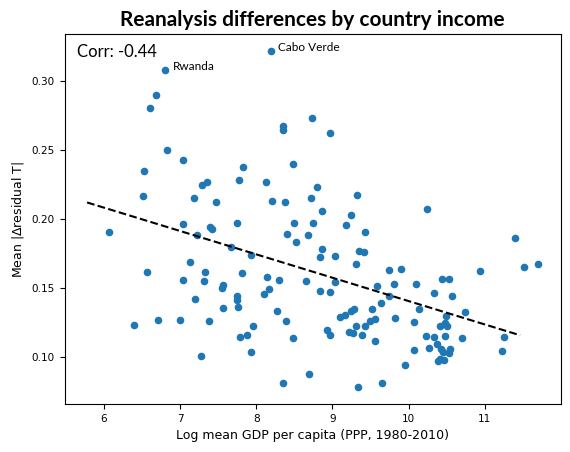

In [448]:
var = 'log_gdp'

xlabels = {'log_gdp':'Log mean GDP per capita (PPP, 1980-2010)',
           'mean_T':'1980-2010 mean temperature'}
titles = {'log_gdp':'Reanalysis differences by country income',
          'mean_T':'Reanalysis differences by mean temperature'}
           

ax = plt.subplot()

plot_data = pc_x.set_index('countryname').loc[:,['mean_mad',var]]
pc_x.plot.scatter(y='mean_mad',x=var,ax=ax,color='tab:blue')

# Label the two countries sampled
for cntry in ds_disagree.countryname.values:
    ax.annotate(cntry,
                (plot_data.loc[cntry].values[::-1]) + np.array([np.diff(ax.get_xlim())[0]*0.015,0]),
                font=extra_fonts['lato'])

# Linear fit, removing any potential nans first
pd_tmp = pc_x.copy()
pd_tmp = pd_tmp.dropna(how='any')
reg = sklearn.linear_model.LinearRegression().fit(X = np.atleast_2d(pd_tmp[var]).T,
                                           y = np.atleast_1d(pd_tmp['mean_mad']))

xs = np.arange(ax.get_xlim()[0],ax.get_xlim()[1],
              (ax.get_xlim()[1]-ax.get_xlim()[0])/12)
plt.plot(xs,reg.predict(np.atleast_2d(xs).T),'k',linestyle='--')

# Correlation 
corr = pd_tmp.loc[:,('mean_mad',var)].corr().values[0,1]
corr = np.round(corr,2)
ax.annotate('Corr: '+str(corr),
            (0.025,0.975),xycoords = 'axes fraction',
            fontsize=12,font=extra_fonts['lato'],
            ha='left',va='top')

# Annotations
ax.set_title(titles[var],
            font=extra_fonts['lato-bold'],fontsize=15)
ax.set_xlabel(xlabels[var])
ax.set_ylabel(r'Mean |$\Delta$residual T|')


/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/obs_diffs_diag_gdppc.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/extra_figs/obs_diffs_diag_gdppc.png saved!


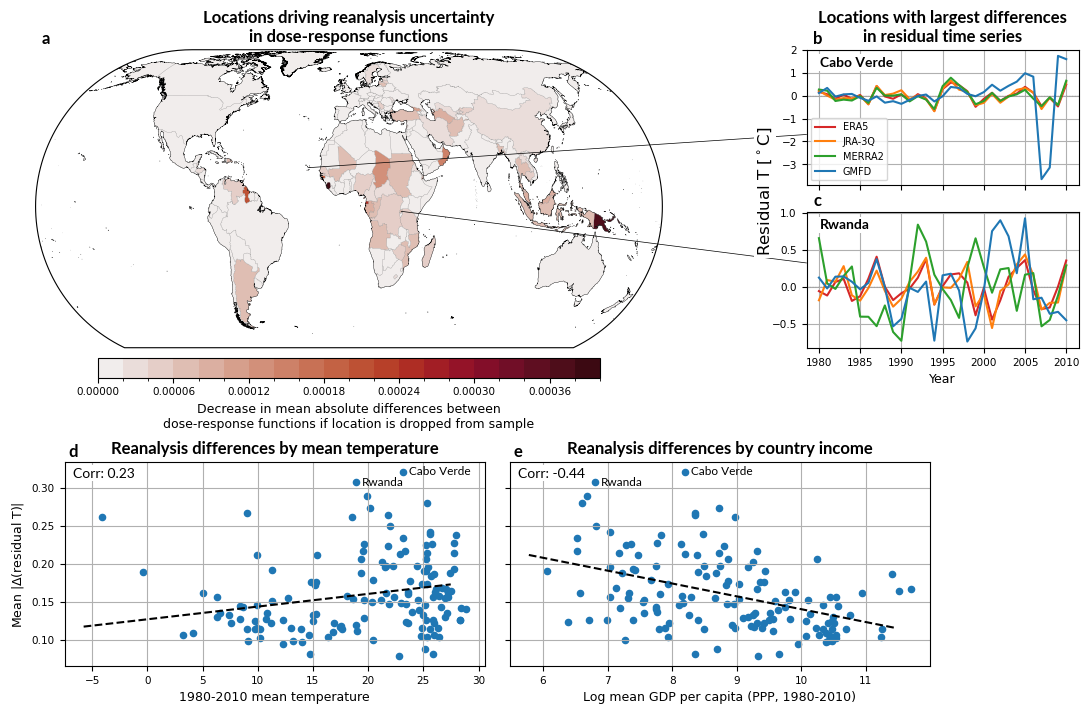

In [71]:
save_fig = True
output_fn = f'{dir_list['figs']}extra_figs/obs_diffs_diag_gdppc'

levels = 20
cbar_params = {'vmin':0,'vmax':0.0004,'levels':20,'cmap':cmocean.cm.amp}

thresh = 0.85

projs = {'dmortality':ccrs.EckertIV(),
         'dgdppc':ccrs.EckertIV(),
         'dpayroll':ccrs.AlbersEqualArea(central_longitude=-100,central_latitude=35)}

bbox_params = {'facecolor':'w','edgecolor':'none','pad':1.5}

fig = plt.figure(figsize=(15,8))
gs = plt.GridSpec(nrows=4,ncols=8,height_ratios = [1,1,0.45,1.5],
                  wspace=0.2,hspace=0.2)

proc = 'gdppc'
    
# Load shapefile and process centroids
gdf = load_shp(proc)
centroids = gdf.geometry.to_crs('EPSG:4087').centroid
centroids = centroids.to_crs('EPSG:4326')
centroids = centroids.to_frame(name='geometry')
centroids['locid'] = gdf.locid.values
centroids = centroids.set_index('locid')

# Residual time series data
ds_resid = resid.set_index(['countryname','year','obs_mod']).to_xarray()
ds_disagree = ds_resid.sel(countryname=disagr.countryname.values)
ds_disagree['obs_mod'] = [re.sub(r'\-025','',mod) for mod in ds_disagree.obs_mod.values]

# Mean MADs between dose-response functions
mean_merged = gdf.merge(
                        mean_abs.rename(columns={"country": "locid_join"}),
                        left_on="locid", right_on="locid_join", how="left"
                        )

#--------------------------------
# Map ---------------------------
#--------------------------------
row_idx = 0
ax_map = fig.add_subplot(gs[(row_idx*2):(row_idx*2+2),0:6],projection=projs['d'+proc])
plot_data = mean_merged[['locid','geometry','mean_abs_reduction']]
# Get just the places for which dropping them reduces the obs. uncertainty
plot_data.loc[:,'mean_abs_reduction'] = plot_data['mean_abs_reduction'].where(plot_data['mean_abs_reduction']>0,0)
plot_data = plot_data.set_index('locid')['mean_abs_reduction'].to_xarray()

if 'levels' in cbar_params:
    gdf['colors'],bins,colors_ref = create_segcmap(plot_data.sel(locid = gdf.locid.values),
                                    cbar_params,
                                   centered = False,return_all = True)
    gdf_tmp = gdf.dissolve(by='colors').reset_index()
    
    gdf_tmp.plot(color=gdf_tmp.colors,edgecolor='none',transform=ccrs.PlateCarree(),ax=ax_map)
    # Plot national boundaries at least
    if proc == 'gdppc':
        gdf.plot(ax=ax_map,facecolor='none',edgecolor='grey',linewidth=0.1,transform=ccrs.PlateCarree())
        
else:
    fig,ax_map = plot_map(plot_data.sel(poly_idx = gdf.locid.values),
         gdf,**cbar_params,fig=fig,ax=ax_map)

if proc == 'payroll':
    ax_map.coastlines(lw=0.5)
else:
    gpd.GeoSeries(data = gdf.union_all()).plot(facecolor='none',edgecolor='k',linewidth=0.25,ax=ax_map, 
                                          transform=ccrs.PlateCarree())
if row_idx == 0:
    ax_map.set_title(f'Locations driving reanalysis uncertainty\nin dose-response functions',
                     font=extra_fonts['lato-bold'],fontsize=12)

if proc == 'payroll':
    ax_map.set_extent((-135, -64, 23.7, 50.6),
                      crs = ccrs.PlateCarree())

# Subplot label
ax_map.annotate(string.ascii_lowercase[row_idx*3],(0.01,1.01),xycoords = 'axes fraction',
                        fontweight='bold',fontsize=12,va='bottom',font=extra_fonts['lato-bold'])

# Colorbar
mappos = ax_map.get_position()

cbar = add_colorbar(cbar_params,
             orientation='horizontal',
             #axpos = (mappos.x0-mappos.size[0]*0.025,
             #         mappos.y0 + mappos.size[1]*0.1,
             #         0.015,
             #         mappos.size[1]*0.8),
             axpos = (mappos.x0 + mappos.size[0]*0.1,
                         mappos.y0 - mappos.size[1]*0.1,
                         mappos.size[0]*0.8,
                         0.025),
             fig=fig,
             label=('Decrease in mean absolute differences between\n'+
                    'dose-response functions if location is dropped from sample'),
                    )
cbar.ax.yaxis.set_ticks_position('left')
cbar.ax.yaxis.set_label_position('left')
#--------------------------------
# Sample plots ------------------
#--------------------------------
sample_axs = []
for plt_idx,reg in enumerate(ds_disagree.countryname.values):

    centroid = centroids.loc[reg,:].iloc[0]
    
    colors = {'ERA5':'tab:red',
              'JRA-3Q':'tab:orange',
              'MERRA2':'tab:green',
             'GMFD':'tab:blue'}
    
    ax = fig.add_subplot(gs[row_idx*2+plt_idx,6:8])
    
    for mod,color in colors.items():
        ds_disagree.sel(obs_mod=mod,countryname=reg).resid.plot(color=color,label=mod)
    
    ax.axhline(0,color='k',linestyle=':',lw=0.2)


    #ax.set_ylabel(r'Residual T [$^\circ$C]',
    #              bbox=bbox_params,zorder=5)
    ax.set_ylabel('')
    if (plt_idx == 0) and (row_idx == 0):
        ax.legend(fontsize=7,loc='lower left')
        ax.set_xlabel('')
        ax.set_title('Locations with largest differences\n'+
                     'in residual time series',
                    font=extra_fonts['lato-bold'],fontsize=12)
        ax.set_xticklabels([])
    elif (plt_idx == 1):
        ax.set_xlabel('Year')
        ax.set_title('')
    ax.annotate(reg,(0.05,0.95),xycoords='axes fraction',va='top',
                font=extra_fonts['lato-bold'],fontsize=10,
                bbox=bbox_params)

    ax.grid()

    # Subplot label
    ax.annotate(string.ascii_lowercase[row_idx*3+plt_idx+1],(0.025,1.025),xycoords = 'axes fraction',
                            fontweight='bold',fontsize=12,va='bottom',ha='left',font=extra_fonts['lato-bold'])
    

    # Map point → figure coordinates
    lon_proj,lat_proj = ax_map.projection.transform_point(centroid.x, centroid.y, ccrs.PlateCarree())
    disp = ax_map.transData.transform((lon_proj, lat_proj))  # PlateCarree input
    map_fig = fig.transFigure.inverted().transform(disp)

    # add connection to main map
    if plt_idx == 0: 
        yloc = 0.375
    elif plt_idx == 1:
        yloc = 0.625
    con = mpl.patches.ConnectionPatch(
        #xyA=(centroid.x, centroid.y), coordsA=ax_map.transData,   # map location (lon/lat)
        xyA = map_fig, coordsA = fig.transFigure,
        xyB=(0.0, yloc), coordsB=ax.transAxes,       # left-center of subplot
        axesA=ax_map,
        axesB=ax,
        color='black',
        lw=0.5,
        zorder=1
    )
    
    ax.add_artist(con)
    con.set_zorder(1)
    sample_axs.append(ax)

ax_pos = [sample_axs[0].get_position(),
          sample_axs[1].get_position()]
center_between_axes = ax_pos[1].y1+(ax_pos[0].y0-ax_pos[1].y1)/2

plt.annotate(r'Residual T [$^\circ$C]',
            (0.51,#ax_pos[0].x0-0.1*ax_pos[0].width,
            center_between_axes-0.04),
            xycoords = 'figure fraction',
            ha='center',
            va='center',
            rotation=90,
            fontsize=12,
            bbox = bbox_params,zorder=10)

#--------------------------------
# Scatterplots ------------------
#--------------------------------

xlabels = {'log_gdp':'Log mean GDP per capita (PPP, 1980-2010)',
           'mean_T':'1980-2010 mean temperature'}
titles = {'log_gdp':'Reanalysis differences by country income',
          'mean_T':'Reanalysis differences by mean temperature'}
for plt_idx,var in enumerate(['mean_T','log_gdp']):
    ax = fig.add_subplot(gs[3,1+plt_idx*3:1+(plt_idx+1)*3])
    
    plot_data = pc_x.set_index('countryname').loc[:,['mean_mad',var]]
    pc_x.plot.scatter(y='mean_mad',x=var,ax=ax,color='tab:blue')
    
    # Label the two countries sampled
    for cntry in ds_disagree.countryname.values:
        ax.annotate(cntry,
                    (plot_data.loc[cntry].values[::-1]) + np.array([np.diff(ax.get_xlim())[0]*0.015,0]),
                    font=extra_fonts['lato'],
                    va='center')
    
    # Linear fit, removing any potential nans first
    pd_tmp = pc_x.copy()
    pd_tmp = pd_tmp.dropna(how='any')
    reg = sklearn.linear_model.LinearRegression().fit(X = np.atleast_2d(pd_tmp[var]).T,
                                               y = np.atleast_1d(pd_tmp['mean_mad']))
    
    xs = np.arange(ax.get_xlim()[0],ax.get_xlim()[1],
                  (ax.get_xlim()[1]-ax.get_xlim()[0])/12)
    plt.plot(xs,reg.predict(np.atleast_2d(xs).T),'k',linestyle='--')
    
    # Correlation 
    corr = pd_tmp.loc[:,('mean_mad',var)].corr().values[0,1]
    corr = np.round(corr,2)
    ax.annotate('Corr: '+str(corr),
                (0.02,0.975),xycoords = 'axes fraction',
                fontsize=10,font=extra_fonts['lato'],
                ha='left',va='top',
                bbox=bbox_params)
    
    # Annotations
    ax.set_title(titles[var],
                font=extra_fonts['lato-bold'],fontsize=12)
    ax.set_xlabel(xlabels[var])
    if plt_idx == 0:
        ax.set_ylabel(r'Mean |$\Delta$(residual T)|')
    else:
        ax.set_ylabel('')
        ax.set_yticklabels([])
    ax.grid()
    # Subplot label
    ax.annotate(string.ascii_lowercase[plt_idx+3],(0.01,1.01),xycoords = 'axes fraction',
                        fontweight='bold',fontsize=12,va='bottom',font=extra_fonts['lato-bold'])



if save_fig:
    utility_print(output_fn)


In [72]:
2

2

## By station density

In [76]:
from shapely import Point\

#gdf = load_shp('gdppc')

station_locs = pd.read_fwf(
    dir_list['aux']+'ghcnd-stations.txt',
    colspecs=[(0, 11), (11, 20), (20, 30), (30, 37), (37, 71)],
    names=['station_id', 'lat', 'lon', 'elev', 'station_name'],
)
station_locs = gpd.GeoDataFrame(station_locs,
                                geometry = [Point(lon,lat) for lon,lat in zip(station_locs.lon.values,station_locs.lat.values)],
                                crs='EPSG:4326')

# Spatial join: jeder Station das Land zuordnen
joined = gpd.sjoin(station_locs, gdf[['locid', 'SQKM_CNTRY', 'geometry']], 
                   how='inner', predicate='within')

# Stationen pro Land zählen und durch Fläche dividieren
density = (joined.groupby('locid')
                 .agg(n_stations=('station_id', 'count'),
                      area_sqkm=('SQKM_CNTRY', 'first'))
                 .assign(station_density=lambda x: x['n_stations'] / x['area_sqkm']))

# Zurück ins gdf mergen falls gewünscht
#gdf = gdf.merge(density, on='locid', how='left')
#gdf['station_density'] = gdf['station_density'].fillna(0)

In [13]:
# ---- Pick 2 most-agreeing + 2 most-disagreeing countries by avg MAD ----
per_country = (pair_mad.groupby(["iso", "countryname"], as_index=False)
                        .agg(mean_mad=("mad", "mean")))
per_country = per_country.merge(cov[["iso", "log_gdp"]], on="iso",
                                 how="left")
# Require at least 25 years of residual data for sensible time-series panels
yr_count = (resid.groupby("countryname")
                 .agg(n_years=("year", "nunique"))
                 .reset_index())
per_country = per_country.merge(yr_count, on="countryname", how="left")
per_country = per_country[per_country["n_years"] >= 25].reset_index(drop=True)

In [60]:
# ---- Bottom row: 2 scatters ----------------------------------------
# Per-country mean MAD (across the 6 pairs) is the y-axis of both
pc_x = per_country.merge(cov[["iso", "mean_T"]], on="iso", how="left")

In [63]:
pc_x = pc_x.set_index('countryname').join(gdf[['locid','station_density','weighted_station_density']].rename({'locid':'countryname'},axis=1).set_index('countryname'))
pc_x['station_density_log'] = np.log(pc_x['station_density'])
pc_x['weighted_station_density_log'] = np.log(pc_x['weighted_station_density'])


/glade/u/home/schwarzwald/.conda/envs/enso_imp/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/glade/u/home/schwarzwald/.conda/envs/enso_imp/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [137]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

# Einlesen
inventory = pd.read_fwf(
    dir_list['aux'] + 'ghcnd-inventory.txt',
    colspecs=[(0, 11), (11, 20), (20, 30), (31, 35), (36, 40), (41, 45)],
    names=['station_id', 'lat', 'lon', 'variable', 'start_year', 'end_year'],
)

# Nur TMAX, TMIN, TAVG
inventory = inventory[inventory['variable'].isin(['TMAX', 'TMIN', 'TAVG'])]

# Nur Stationen mit mindestens einem Jahr in 1980-2010
inventory = inventory[
    (inventory['end_year'] >= 1980) & (inventory['start_year'] <= 2010)
]

# Überlappung mit 1980-2010 berechnen
inventory['years_overlap'] = (
    inventory['end_year'].clip(upper=2010) - 
    inventory['start_year'].clip(lower=1980) + 1
)
inventory['frac_coverage'] = inventory['years_overlap'] / 31  # 1980-2010 = 31 Jahre

# Falls eine Station mehrere Variablen hat: max coverage nehmen
inventory = (inventory.groupby(['station_id', 'lat', 'lon'])
                      .agg(frac_coverage=('frac_coverage', 'max'),
                           variables=('variable', lambda x: list(x)))
                      .reset_index())

# GeoDataFrame
inventory = gpd.GeoDataFrame(
    inventory,
    geometry=[Point(lon, lat) for lon, lat in zip(inventory.lon, inventory.lat)],
    crs='EPSG:4326'
)

In [55]:
import xarray as xr
import xagg as xa
# Load population density
pop = xr.open_dataset(dir_list['aux']+'pop_data/glp00ag30.asc')
pop = xa.fix_ds(pop)
pop = pop.isel(band=0)
pop = pop.rename({'band_data':'pop'}).pop

In [78]:
# 1. Bevölkerungsdichte für jede Station aus pop-DataArray extrahieren
#    (nearest-neighbor lookup auf dem 0.5-Grad Grid)
station_pop = pop.sel(
    lat=xr.DataArray(inventory.lat.values, dims='station'),
    lon=xr.DataArray(inventory.lon.values, dims='station'),
    method='nearest'
).values

inventory['pop_density'] = station_pop

# 2. Gewichteten Score berechnen: frac_coverage * pop_density
inventory['weighted_coverage'] = inventory['frac_coverage'] * inventory['pop_density']

# 3. Spatial join mit gdf
joined = gpd.sjoin(inventory, gdf[['locid', 'SQKM_CNTRY', 'geometry']],
                   how='inner', predicate='within')

# 4. Pro Land aggregieren
density = (joined.groupby('locid')
                 .agg(
                     n_stations=('station_id', 'count'),
                     area_sqkm=('SQKM_CNTRY', 'first'),
                     weighted_coverage_sum=('weighted_coverage', 'sum'),
                     pop_density_sum=('pop_density', 'sum'),
                 )
                 .assign(
                     # Stationendichte (ungewichtet)
                     station_density=lambda x: x['n_stations'] / x['area_sqkm'],
                     # Bevölkerungsgewichtete, zeitlich gewichtete Stationendichte
                     weighted_station_density=lambda x: x['weighted_coverage_sum'] / x['pop_density_sum'],
                 ))

# 5. Zurück ins gdf mergen
#gdf = gdf.merge(density, on='locid', how='left')
#gdf['weighted_station_density'] = gdf['weighted_station_density'].fillna(0)

In [145]:
pix_polys = xa.core.create_raster_polygons(pop.to_dataset())['gdf_pixels']

lat/lon bounds not found in dataset; they will be created.


In [146]:
# 1. pop-Werte zu pix_polys hinzufügen
pop_df = pop.to_dataframe(name='pop_density').reset_index()
pix_polys = pix_polys.merge(pop_df, on=['lat', 'lon'], how='left')

# 2. frac_coverage pro Pixel: Stationen in Pixel joinen
#    (inventory als Punkte, pix_polys als Polygone)
inventory_gdf = gpd.GeoDataFrame(
    inventory,
    geometry=[Point(lon, lat) for lon, lat in zip(inventory.lon, inventory.lat)],
    crs='EPSG:4326'
)

stations_in_pixels = gpd.sjoin(inventory_gdf, pix_polys[['pix_idx', 'geometry']],
                                how='left', predicate='within')

pixel_coverage = (stations_in_pixels.groupby('pix_idx')
                                    .agg(total_coverage=('frac_coverage', 'sum'))
                                    .reset_index())



In [ ]:
pixel_coverage['pix_idx'] = pixel_coverage['pix_idx'].astype(int)
pix_polys = pix_polys.merge(pixel_coverage, on='pix_idx', how='left')
pix_polys['total_coverage'] = pix_polys['total_coverage'].fillna(0)

# 3. Pixel in Länder joinen
pixels_in_countries = gpd.sjoin(pix_polys, gdf[['locid', 'geometry']],
                                 how='inner', predicate='intersects')

# 4. Bevölkerungsgewichteter Durchschnitt pro Land
density = (pixels_in_countries.groupby('locid')
                               .apply(lambda x: np.average(x['total_coverage'], 
                                                           weights=x['pop_density'].clip(lower=0)))
                               .rename('weighted_station_density')
                               .reset_index())


In [163]:
# 3. Pixel in Länder joinen
pixels_in_countries = gpd.sjoin(pix_polys, gdf[['locid', 'geometry']],
                                 how='inner', predicate='intersects')
pixels_in_countries['pop_density'] = pixels_in_countries['pop_density'].where(pixels_in_countries['pop_density']!=0,0.00000001)

In [165]:
density = (pixels_in_countries.groupby('locid')
                               .apply(lambda x: np.average(x['total_coverage'], 
                                                           weights=x['pop_density'].clip(lower=0)))
                               .rename('weighted_station_density')
                               .reset_index())

/glade/derecho/scratch/schwarzwald/tmp/ipykernel_25425/3453349909.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: np.average(x['total_coverage'],


In [173]:
density['logwsd'] = np.log(density.weighted_station_density.where(density.weighted_station_density>0.000001))

In [178]:
gdf2 = gdf.set_index('locid').drop('weighted_station_density',axis=1).join(density.set_index('locid'))

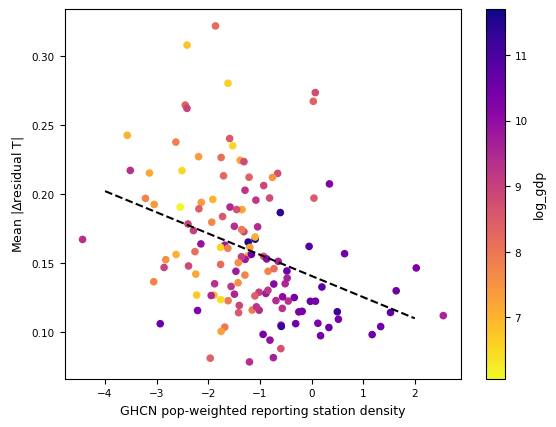

In [231]:
ax = plt.subplot()
plot_data = pc_x.drop('weighted_station_density',axis=1).join(density.set_index('locid'))
plot_data = plot_data[['mean_mad','logwsd','log_gdp']]
plot_data.plot.scatter(y='mean_mad',x='logwsd',ax=ax,c='log_gdp',cmap='plasma_r')
ax.set_xlabel('GHCN pop-weighted reporting station density')
ax.set_ylabel(r'Mean |$\Delta$residual T|')


pd_tmp = plot_data.copy()
pd_tmp = pd_tmp.dropna(how='any')

reg = sklearn.linear_model.LinearRegression().fit(X = np.atleast_2d(pd_tmp.logwsd).T,
                                           y = np.atleast_1d(pd_tmp.mean_mad))

xs = np.arange(-4,2.1)
plt.plot(xs,reg.predict(np.atleast_2d(xs).T),'k',linestyle='--')